# Kaido Motors España: demanda, stock y beneficio

Hilo conductor del trabajo. Responde a las cinco preguntas de la sección 9.1 del
[enunciado](docs/kaido-motors-case-study.md) llamando a las funciones de `src/`.
Ejecutar desde la raíz del repositorio con «reiniciar y ejecutar todo». Las tablas y
figuras se regeneran en `resultados/`.

**Estado:** fases 1 (datos y demanda observada), 2 (previsión de la demanda) y 3
(simulación determinista del escenario central) completadas. Los escenarios con
incertidumbre se añadirán en las fases siguientes.

Términos: **VM**, gasto comercial por coche (descuentos, campañas e incentivos);
**CVP**, lo que queda a la marca después del VM; **PFF**, precio franco fábrica;
**transfer**, coche traído del stock de otro país europeo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import datos

plt.style.use("config/graficos.mplstyle")
TABLAS = Path("resultados/tablas")
FIGURAS = Path("resultados/figuras")
TABLAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

GRIS_OSCURO = "#333333"
GRIS_MEDIO = "#888888"


def formato_es(df, decimales=0, porcentajes=(), dec_pct=1):
    """Presenta una tabla con separador de miles y coma decimal."""
    formatos = {c: f"{{:.{dec_pct}%}}" for c in porcentajes}
    estilo = df.style.format(precision=decimales, thousands=".", decimal=",", na_rep="—")
    for columna, patron in formatos.items():
        estilo = estilo.format(
            lambda x, p=patron: "—" if pd.isna(x) else p.format(x).replace(".", ",").replace("%", " %"),
            subset=[columna],
        )
    return estilo


def guardar_figura(fig, nombre):
    for extension in ["png", "svg"]:
        fig.savefig(FIGURAS / f"{nombre}.{extension}")

## 1. Datos y demanda observada

**Pregunta.** ¿Son fiables y coherentes los datos? ¿Qué parte de las ventas de Kaido
es demanda de clientes y cuánto creció de verdad en A012 (pregunta 1 del caso)?

**Método.** Se cargan los siete CSV respetando que solo las celdas vacías son
ausencias (`NA` es un código de modelo). Se comprueban claves, periodos y coherencia
entre ficheros; se verifica el balance de stock; se construye una serie mensual por
segmento y se marcan los meses que distorsionan la demanda: compras adelantadas y
meses con poco stock disponible.

### 1.1. Carga y comprobaciones

`datos.comprobar_datos` devuelve una fila por comprobación con su resultado y un
detalle cuantificado.

In [2]:
dd = datos.cargar_datos()
comprobaciones = datos.comprobar_datos(dd)
comprobaciones.to_csv(TABLAS / "comprobaciones_datos.csv", index=False)
print(f"Comprobaciones correctas: {comprobaciones['correcto'].sum()} de {len(comprobaciones)}")
comprobaciones

Comprobaciones correctas: 25 de 25


,comprobacion,correcto,detalle
0,Claves únicas en ventas,True,0 duplicados
1,Meses completos en ventas,True,"t 25-144, 21 series"
2,Claves únicas en stock,True,0 duplicados
3,Meses completos en stock,True,"t 97-144, 7 series"
4,Claves únicas en mercado,True,0 duplicados
5,Meses completos en mercado,True,"t 1-144, 21 series"
6,Claves únicas en economia,True,0 duplicados
7,Meses completos en economia,True,"t 1-144, 1 series"
8,Segmentos y canales esperados,True,"7 segmentos, 3 canales"
9,Calendario A013 con 12 meses (t 145-156),True,12 meses


Todas las comprobaciones son correctas. Se observan los 125.030 coches del anexo 5,
las ventas de Kaido coinciden con `marca_propia` del mercado en todas las celdas y
las fichas de segmentos y modelos cuadran con las ventas. Las ausencias responden a
la cobertura descrita en el enunciado: edad de ventas desde A009-02, `wholesale`
desde A009-02 y `pct_renting` desde A004.

### 1.2. Balance de stock

Se comprueba $S_t = S_{t-1} + W_t - M_t$, donde $S$ es el stock en la red a fin de
mes, $W$ la facturación a la red (`wholesale`) y $M$ las matriculaciones de Kaido,
todo en coches. El residuo es la diferencia entre el stock observado y el que
resulta de la cuenta. Se repite con las matriculaciones sin automatriculaciones para
ver cuál de las dos versiones usa el balance original.

In [3]:
balance = datos.balance_stock(dd).dropna(subset=["residuo"])
resumen_balance = balance.groupby("segmento").agg(
    meses=("residuo", "size"),
    meses_con_residuo=("residuo", lambda x: (x != 0).sum()),
    residuo_max_abs=("residuo", lambda x: x.abs().max()),
    residuo_acumulado=("residuo", "sum"),
    residuo_medio_sin_automatriculacion=("residuo_sin_automatriculacion", "mean"),
).reindex(datos.SEGMENTOS)
display(formato_es(resumen_balance, decimales=1))
balance.loc[balance["residuo"].abs() > 5, ["segmento", "periodo", "stock_anterior",
                                           "wholesale", "unidades", "stock_total",
                                           "residuo"]]

,meses,meses_con_residuo,residuo_max_abs,residuo_acumulado,residuo_medio_sin_automatriculacion
segmento,,,,,
B,47,8,"1,0","0,0","-17,2"
C,47,30,"2,0","0,0","-36,7"
MD,47,8,"8,0","0,0","-14,6"
SSUV,47,21,"51,0","-2,0","-40,1"
CSUV,47,0,"0,0","0,0","-5,2"
MSUV,47,31,"5,0","0,0","-42,6"
S,47,4,"1,0","0,0","-7,2"


,segmento,periodo,stock_anterior,wholesale,unidades,stock_total,residuo
158,MD,A0100301,331.0,119.0,128,314,-8.0
159,MD,A0100401,314.0,121.0,125,318,8.0
293,SSUV,A0090601,781.0,289.0,493,628,51.0
294,SSUV,A0090701,628.0,254.0,354,478,-50.0


El balance se cumple con las **matriculaciones totales**: el residuo acumulado es
cero en todos los segmentos salvo SSUV (−2 coches) y casi todos los residuos son de
±1 a ±5 coches que se compensan al mes siguiente. Solo hay dos pares mayores, también
compensados: SSUV en A009-06/07 (+51/−50) y MD en A010-03/04 (−8/+8); parecen
registros imputados a un mes contiguo y no se corrigen. Con la demanda sin
automatriculaciones el residuo medio es de −5 a −43 coches al mes por segmento: las
automatriculaciones salen del stock y el simulador deberá tratarlas como salida de
la red aunque no sean demanda.

### 1.3. Serie mensual por segmento

`datos.serie_mensual_segmento` agrega los tres canales y define:

- `demanda_observada` = matriculaciones − automatriculaciones (coches). Se supone que
  la automatriculación no es demanda de clientes (tabla 1 del enunciado). Las ventas
  especiales sí lo son y no se restan.
- `cuota` = matriculaciones de Kaido / mercado del segmento (incluye Kaido).
- `en_venta`: 1 desde la primera venta del segmento. Los ceros anteriores (SSUV antes
  de A008-04, MSUV antes de A005, CSUV antes de A012-08) son ausencia de producto,
  no demanda nula.
- Sucesos y calendario de `economia_eventos_mensuales.csv`.
- `senal_falta_stock`: 1 si el stock sin cliente a fin de mes es menor que media venta
  mensual del segmento (menos de unas dos semanas libres). Vacío antes de A009,
  cuando no hay datos de stock.

La serie se guarda en `resultados/tablas/serie_mensual_segmento_a003_a012.csv`.

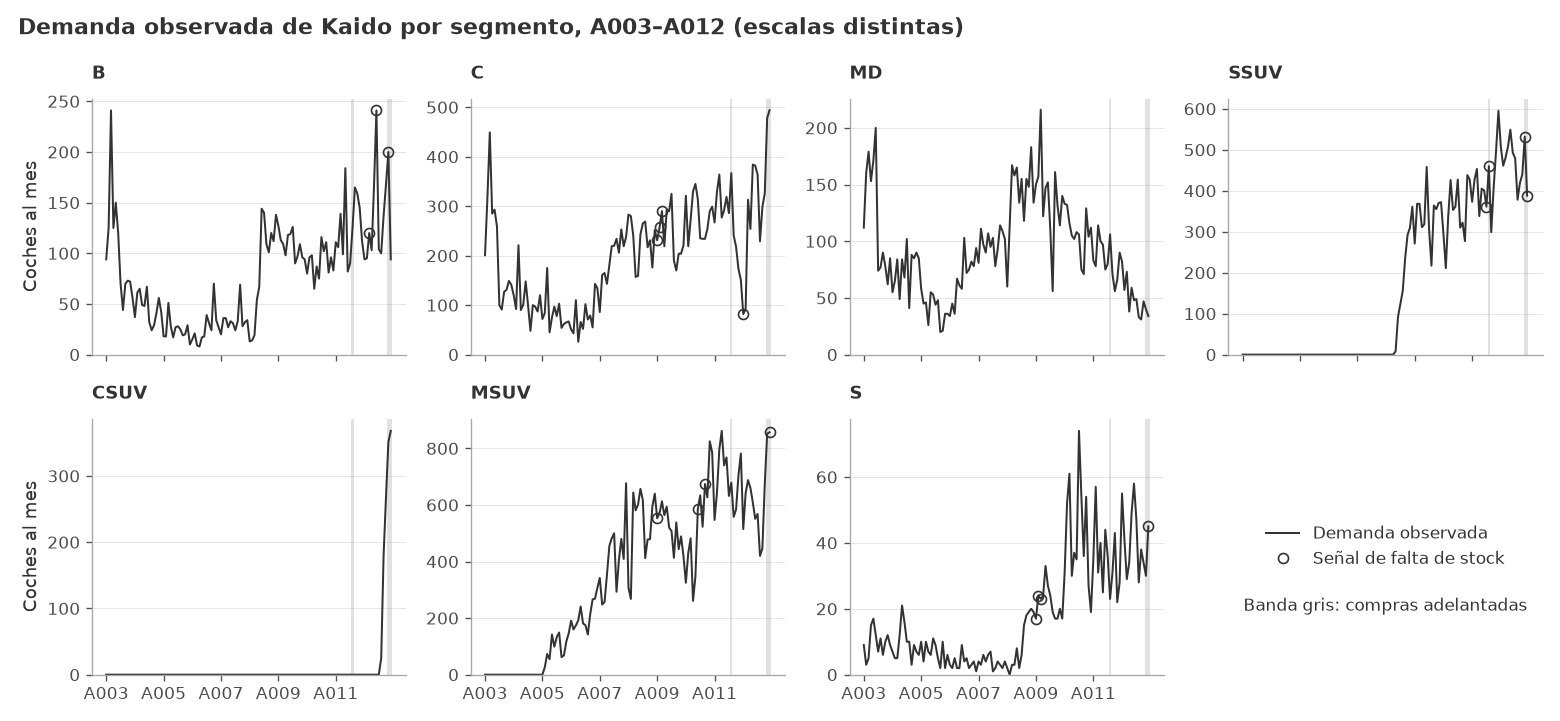

In [4]:
serie = datos.serie_mensual_segmento(dd)
serie.drop(columns="fecha").to_csv(
    TABLAS / "serie_mensual_segmento_a003_a012.csv", index=False
)

fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for eje, segmento in zip(ejes.flat, datos.SEGMENTOS):
    s = serie[serie["segmento"] == segmento]
    eje.plot(s["t"], s["demanda_observada"], color=GRIS_OSCURO, lw=1.2,
             label="Demanda observada")
    for t in s.loc[s["adelanto_compras"] == 1, "t"]:
        eje.axvspan(t - 0.5, t + 0.5, color=GRIS_MEDIO, alpha=0.25, lw=0)
    falta = s[s["senal_falta_stock"] == 1]
    eje.plot(falta["t"], falta["demanda_observada"], "o", mfc="none",
             mec=GRIS_OSCURO, ms=6, label="Señal de falta de stock")
    eje.set_title(segmento, fontsize=11)
    eje.set_ylim(bottom=0)
ejes.flat[-1].axis("off")
ejes.flat[-1].legend(*ejes.flat[0].get_legend_handles_labels(), loc="center")
ejes.flat[-1].text(0.5, 0.25, "Banda gris: compras adelantadas", ha="center",
                   transform=ejes.flat[-1].transAxes, fontsize=10)
inicios = list(range(25, 145, 24))
for eje in ejes[1]:
    eje.set_xticks(inicios, [f"A{(t - 1) // 12 + 1:03d}" for t in inicios])
for eje in ejes[:, 0]:
    eje.set_ylabel("Coches al mes")
fig.suptitle("Demanda observada de Kaido por segmento, A003–A012 "
             "(escalas distintas)", x=0.01, ha="left", fontweight="bold")
guardar_figura(fig, "demanda_observada_segmento_a003_a012")
plt.show()

Fuente: `ventas_kaido_mensuales.csv`, `stock_red_mensual.csv` y
`economia_eventos_mensuales.csv`, A003–A012. Las escalas son distintas para comparar
patrones, no magnitudes. Se observan tres tipos de segmento: consolidados con
tendencia (C, MSUV, SSUV), en declive (MD desde A009) y pequeños y volátiles (B, S).
CSUV solo tiene cinco meses de historia y todos en fase de lanzamiento, así que no
tiene una cuota comparable y necesitará un tratamiento propio en la fase 2.

### 1.4. Señales de falta de stock

En un mes sin coches disponibles las ventas son una cota inferior de la demanda. No se
puede saber cuánto más se habría vendido, así que estos meses se marcan pero no se
corrigen.

In [5]:
falta = serie[serie["senal_falta_stock"] == 1].assign(
    stock_libre_meses=lambda d: d["s_sin_cliente"] / d["matriculaciones"]
)[["segmento", "periodo", "matriculaciones", "stock_total", "s_sin_cliente",
   "stock_libre_meses", "adelanto_compras"]]
con_stock = serie["stock_total"].notna().sum()
print(f"Meses con señal: {len(falta)} de {con_stock} segmento-mes con datos de stock")
formato_es(falta.reset_index(drop=True), decimales=2)

Meses con señal: 19 de 336 segmento-mes con datos de stock


,segmento,periodo,matriculaciones,stock_total,s_sin_cliente,stock_libre_meses,adelanto_compras
0,B,A0120301,127,"140,00","54,00","0,43",0
1,B,A0120601,271,"207,00","109,00","0,40",0
2,B,A0121101,204,"112,00","59,00","0,29",1
3,C,A0090101,246,"479,00","117,00","0,48",0
4,C,A0090201,282,"468,00","130,00","0,46",0
5,C,A0090301,384,"411,00","187,00","0,49",0
6,C,A0120101,147,"108,00","67,00","0,46",0
7,SSUV,A0110701,429,"267,00","203,00","0,47",0
8,SSUV,A0110801,485,"359,00","235,00","0,48",1
9,SSUV,A0121101,552,"538,00","247,00","0,45",1


La señal aparece en 19 de los 336 segmento-mes con datos de stock y se concentra en
dos periodos: el primer trimestre de A009 (C, S y MSUV) y noviembre y diciembre de
A012, cuando las compras adelantadas vaciaron la red. En diciembre de A012 SSUV
terminó con 0 coches y S con 1, de modo que la demanda de esos meses pudo ser mayor
que la observada. Antes de A009 no se puede detectar esta restricción. En la fase 2
se compararán los modelos con y sin estos meses.

### 1.5. Diagnóstico de A012

Comparación anual A011–A012 por segmento. `var_demanda_ene_jul_pct` compara solo
enero–julio, los meses sin sucesos en ninguno de los dos años (en A011 hubo
compras adelantadas en agosto y caída de septiembre a diciembre). La cobertura de
diciembre es el stock dividido entre la media mensual de matriculaciones de A012,
el mismo criterio que la sección 7.1 del enunciado.

In [6]:
anual = (
    serie[serie["anio"].isin(["A011", "A012"])]
    .groupby(["segmento", "anio"], observed=True)
    [["matriculaciones", "automatriculaciones", "demanda_observada", "mercado"]]
    .sum()
    .unstack("anio")
)
ene_jul = (
    serie[serie["anio"].isin(["A011", "A012"]) & (serie["mes"] <= 7)]
    .groupby(["segmento", "anio"], observed=True)["demanda_observada"].sum()
    .unstack("anio")
)
dic = serie[serie["periodo"] == "A0121201"].set_index("segmento")

diagnostico = pd.DataFrame({
    "matriculaciones_a011": anual[("matriculaciones", "A011")],
    "matriculaciones_a012": anual[("matriculaciones", "A012")],
    "automatriculacion_a012_pct": anual[("automatriculaciones", "A012")]
        / anual[("matriculaciones", "A012")],
    "demanda_a011": anual[("demanda_observada", "A011")],
    "demanda_a012": anual[("demanda_observada", "A012")],
    "var_demanda_pct": anual[("demanda_observada", "A012")]
        / anual[("demanda_observada", "A011")] - 1,
    "var_demanda_ene_jul_pct": ene_jul["A012"] / ene_jul["A011"] - 1,
    "var_mercado_pct": anual[("mercado", "A012")] / anual[("mercado", "A011")] - 1,
    "cuota_a012_pct": anual[("matriculaciones", "A012")] / anual[("mercado", "A012")],
    "stock_dic_a012": dic["stock_total"],
    "cobertura_dic_meses": dic["stock_total"]
        / (anual[("matriculaciones", "A012")] / 12),
    "stock_mas_90_dic_pct": dic["stock_mas_90"] / dic["stock_total"],
}).reindex(datos.SEGMENTOS).replace([np.inf, -np.inf], np.nan)
total = diagnostico.filter(regex="^(matric|demanda|stock_dic)").sum()
total["automatriculacion_a012_pct"] = (
    anual[("automatriculaciones", "A012")].sum() / total["matriculaciones_a012"]
)
total["var_demanda_pct"] = total["demanda_a012"] / total["demanda_a011"] - 1
total["var_demanda_ene_jul_pct"] = ene_jul["A012"].sum() / ene_jul["A011"].sum() - 1
total["var_mercado_pct"] = (
    anual[("mercado", "A012")].sum() / anual[("mercado", "A011")].sum() - 1
)
total["cuota_a012_pct"] = total["matriculaciones_a012"] / anual[("mercado", "A012")].sum()
total["cobertura_dic_meses"] = total["stock_dic_a012"] / (total["matriculaciones_a012"] / 12)
total["stock_mas_90_dic_pct"] = dic["stock_mas_90"].sum() / dic["stock_total"].sum()
diagnostico.loc["Total"] = total
diagnostico.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "diagnostico_segmento_a011_a012.csv", index=False
)
porcentajes = [c for c in diagnostico if c.endswith("_pct")]
formato_es(diagnostico, decimales=0, porcentajes=porcentajes).format(
    "{:.1f}", subset=["cobertura_dic_meses"], decimal=","
)

,matriculaciones_a011,matriculaciones_a012,automatriculacion_a012_pct,demanda_a011,demanda_a012,var_demanda_pct,var_demanda_ene_jul_pct,var_mercado_pct,cuota_a012_pct,stock_dic_a012,cobertura_dic_meses,stock_mas_90_dic_pct
segmento,,,,,,,,,,,,
B,1.793,1.764,"8,0 %",1.517,1.623,"7,0 %","13,9 %","-11,5 %","0,8 %",97,"0,7","0,0 %"
C,3.531,4.189,"11,8 %",3.284,3.696,"12,5 %","-12,3 %","-14,6 %","2,5 %",1.107,"3,2","43,3 %"
MD,1.167,755,"21,7 %",1.016,591,"-41,8 %","-35,2 %","-28,6 %","3,7 %",125,"2,0","86,4 %"
SSUV,5.526,6.230,"9,6 %",5.015,5.635,"12,4 %","26,1 %","11,7 %","4,2 %",0,"0,0",—
CSUV,0,1.435,"16,9 %",0,1.192,—,—,"5,3 %","0,8 %",1.011,"8,5","32,3 %"
MSUV,8.815,8.213,"8,9 %",8.296,7.481,"-9,8 %","-15,1 %","7,4 %","5,2 %",536,"0,8","18,8 %"
S,530,589,"17,1 %",415,488,"17,6 %","16,8 %","-7,4 %","73,3 %",1,"0,0","100,0 %"
Total,21.362,23.175,"10,7 %",19.543,20.706,"6,0 %","-3,1 %","-3,4 %","2,6 %",2.877,"1,5","35,3 %"


Las matriculaciones crecieron un 8,5 %, pero la demanda observada solo un 6,0 %: las
automatriculaciones pasaron del 8,5 % al 10,7 % de las matriculaciones. En los meses
comparables (enero–julio) la demanda cayó un 3,1 %, en línea con el mercado (−3,4 %).

Por segmento hay comportamientos opuestos. SSUV creció con su mercado (+12,4 % frente
a +11,7 %). MSUV, el mayor segmento, perdió un 9,8 % mientras su mercado crecía un
7,4 %. MD cayó un 41,8 %, más que su mercado (−28,6 %). C creció en el año, pero cayó
un 12,3 % en enero–julio y cerró con 3,2 meses de cobertura y un 43 % de su stock
con más de 90 días. Que la demanda baje no explica por sí solo la falta de stock de
SSUV y S en diciembre: el problema es el reparto del stock entre segmentos, no solo
su volumen total.

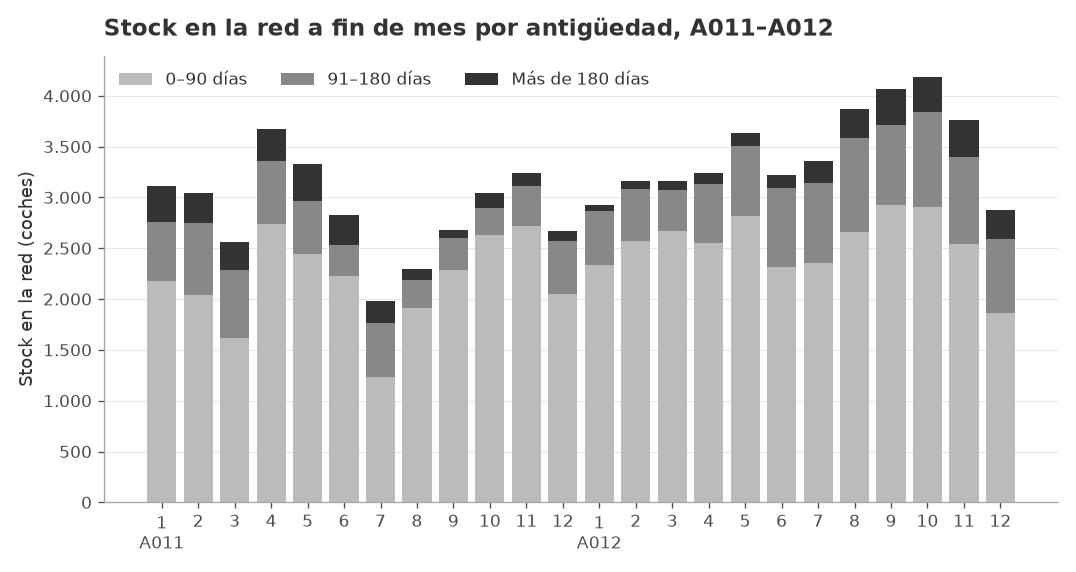

In [7]:
red = (
    dd["stock"][dd["stock"]["anio"].isin(["A011", "A012"])]
    .groupby(["t", "anio", "mes"], as_index=False)[["s_0_90", "s_91_180", "s_mas_180"]]
    .sum()
)
fig, eje = plt.subplots()
base = np.zeros(len(red))
tramos = [("s_0_90", "0–90 días", "#BBBBBB"),
          ("s_91_180", "91–180 días", GRIS_MEDIO),
          ("s_mas_180", "Más de 180 días", GRIS_OSCURO)]
for columna, etiqueta, color in tramos:
    eje.bar(red["t"], red[columna], bottom=base, color=color, label=etiqueta, width=0.8)
    base += red[columna].to_numpy()
eje.set_xticks(red["t"], [f"{m}\n{a}" if m == 1 else str(m)
                          for m, a in zip(red["mes"], red["anio"])])
eje.set_ylabel("Stock en la red (coches)")
eje.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", "."))
eje.set_title("Stock en la red a fin de mes por antigüedad, A011–A012")
eje.legend(ncols=3, loc="upper left")
guardar_figura(fig, "stock_red_antiguedad_a011_a012")
plt.show()

Fuente: `stock_red_mensual.csv`, A011–A012. Se observa lo que describe el caso: el
stock pasó de 2.930 coches en enero a 4.186 en octubre y bajó a 2.877 en diciembre,
pero el peso de los coches con más de 90 días subió del 20 % al 35 %. Las compras de
fin de año vaciaron sobre todo el stock reciente. El simulador deberá partir de este
stock envejecido en enero de A013.

### 1.6. Compras adelantadas y crecimiento real de la demanda

**Método.** Se estima cuánta demanda de noviembre y diciembre de A012 fue adelantada
desde A013. El valor esperado de esos dos meses es la demanda de enero–octubre de
A012 multiplicada por la proporción noviembre–diciembre / enero–octubre de un año de
referencia sin sucesos (A009 y A010). Se excluye CSUV, que no tiene historia. Se
usan las dos referencias por separado: su diferencia mide la incertidumbre del
método. Como comprobación, se repite con la cuota de Kaido sobre su mercado.

In [8]:
adelanto = datos.exceso_adelanto(serie)
cuota_base = (
    serie[(serie["anio"] == "A012") & (serie["mes"] <= 10) & (serie["segmento"] != "CSUV")]
    [["demanda_observada", "mercado"]].sum()
)
display(formato_es(adelanto, decimales=0).format("{:.3f}", subset=["proporcion_evento_base"],
                                                 decimal=","))

# Comprobación cruzada con la cuota sobre el mercado del mismo segmento.
cruzada = []
for referencia in ["A009", "A010"]:
    r = serie[(serie["anio"] == referencia) & (serie["segmento"] != "CSUV")]
    cuota = lambda d: d["demanda_observada"].sum() / d["mercado"].sum()
    salto = cuota(r[r["mes"] >= 11]) / cuota(r[r["mes"] <= 10])
    a012 = serie[(serie["anio"] == "A012") & (serie["mes"] >= 11) & (serie["segmento"] != "CSUV")]
    esperado = a012["mercado"].sum() * cuota_base["demanda_observada"] / cuota_base["mercado"] * salto
    cruzada.append({"referencia": referencia, "esperado": esperado,
                    "exceso": a012["demanda_observada"].sum() - esperado})
formato_es(pd.DataFrame(cruzada))

,referencia,proporcion_evento_base,observado,esperado,exceso
0,A009,"0,184",4.044,2.854,1.190
1,A010,"0,261",4.044,4.042,2


,referencia,esperado,exceso
0,A009,2.735,1.309
1,A010,3.584,460


El exceso estimado va de unos 0 coches (referencia A010) a unos 1.200 (A009). Con
la cuota sobre el mercado se obtienen entre unos 460 y 1.300 coches. La estimación es muy incierta porque el peso
de fin de año en Kaido cambia mucho entre años, y debe leerse como un rango, no como
una cifra. Además, el mercado de estos segmentos no muestra un repunte en
noviembre–diciembre de A012: el aumento es propio de Kaido. La falta de stock
de diciembre limitó las ventas, así que el adelanto real pudo ser mayor. Queda
registrado como discrepancia con la narrativa del enunciado (sección 1).

In [9]:
csuv_a012 = serie[(serie["anio"] == "A012") & (serie["segmento"] == "CSUV")]
exceso_central = adelanto["exceso"].mean()
exceso_min, exceso_max = adelanto["exceso"].min(), adelanto["exceso"].max()
d011 = serie.loc[serie["anio"] == "A011", "demanda_observada"].sum()
m011 = serie.loc[serie["anio"] == "A011", "matriculaciones"].sum()
m012 = serie.loc[serie["anio"] == "A012", "matriculaciones"].sum()
d012 = serie.loc[serie["anio"] == "A012", "demanda_observada"].sum()
d012_sin_csuv = d012 - csuv_a012["demanda_observada"].sum()

pasos = pd.DataFrame(
    [
        ("Matriculaciones", m011, m012),
        ("Demanda observada (sin automatriculaciones)", d011, d012),
        ("Demanda sin el lanzamiento de CSUV", d011, d012_sin_csuv),
        ("Demanda subyacente, adelanto central", d011, d012_sin_csuv - exceso_central),
        ("Demanda subyacente, adelanto mínimo", d011, d012_sin_csuv - exceso_min),
        ("Demanda subyacente, adelanto máximo", d011, d012_sin_csuv - exceso_max),
    ],
    columns=["concepto", "a011", "a012"],
)
pasos["variacion_pct"] = pasos["a012"] / pasos["a011"] - 1
pasos.to_csv(TABLAS / "crecimiento_demanda_a012.csv", index=False)
formato_es(pasos.set_index("concepto"), porcentajes=["variacion_pct"])

,a011,a012,variacion_pct
concepto,,,
Matriculaciones,21.362,23.175,"8,5 %"
Demanda observada (sin automatriculaciones),19.543,20.706,"6,0 %"
Demanda sin el lanzamiento de CSUV,19.543,19.514,"-0,1 %"
"Demanda subyacente, adelanto central",19.543,18.918,"-3,2 %"
"Demanda subyacente, adelanto mínimo",19.543,19.512,"-0,2 %"
"Demanda subyacente, adelanto máximo",19.543,18.324,"-6,2 %"


**Respuesta a la pregunta 1.** El crecimiento del 8,5 % de las matriculaciones en A012
no es crecimiento de la demanda. Al quitar las automatriculaciones queda un 6,0 %;
al quitar además el lanzamiento de CSUV, −0,1 %; y al descontar el adelanto de
noviembre–diciembre, la demanda subyacente se estima entre −0,2 % y −6,2 %, con un
valor central de −3,2 %. Esa cifra central coincide con la caída de enero–julio
(−3,1 %) y con la del mercado (−3,4 %). Se supone que el adelanto de agosto de A011
y su caída posterior se compensaron dentro de A011.

**Consecuencia.** La previsión de A013 no debe partir del nivel de A012. Además, A013
empezará con la caída que suele seguir a un adelanto: hasta unos 1.200 coches de
demanda ya se vendieron en A012.

### 1.7. Decisiones para la fase 2

| Decisión | Supuesto adoptado | Justificación | Efecto esperado |
|---|---|---|---|
| Variable objetivo | Demanda observada (sin automatriculaciones) | Las automatriculaciones no son demanda (tabla 1) | Previsiones más bajas que las matriculaciones; las automatriculaciones se tratarán aparte en el simulador |
| Compras adelantadas | Variables `adelanto_compras` y `caida_tras_adelanto` en el modelo, sin corregir la serie | El exceso es muy incierto (0–1.200 coches) y A011 aporta un episodio completo para estimar su efecto | La caída de principios de A013 sale del modelo y no de un ajuste manual |
| Falta de stock | Señal, sin imputar demanda | No se puede saber la demanda no servida | Comparar el ajuste con y sin esos 19 meses |
| CSUV | Fuera de la cuota histórica; tratamiento de lanzamiento | Cinco meses de historia, todos de lanzamiento | Supuesto explícito de cuota para A013 |
| Validación | Entrenar hasta A011 y comprobar A012 | Sección 5.2 del enunciado | Error = previsión − observado |

## 2. Previsión de la demanda

**Pregunta.** ¿Cuánto venderemos en A013 en cada segmento y con qué fiabilidad (pregunta 2 del caso)?

**Datos y método.** La demanda de Kaido se prevé como `mercado del segmento × cuota de Kaido` (sección 5.2 del enunciado). Se valida entrenando hasta A011 y comparando con A012, y se compara con una referencia sin modelo: la demanda del mismo mes del año anterior. El código está en `src/demanda.py`.

### 2.1. Modelo y decisiones

**Mercado.** Se modela la variación interanual del logaritmo del mercado de cada segmento (suma de los tres canales) con una sola regresión común a los siete segmentos, ponderada por la raíz del mercado del mes base. Comparar cada mes con el mismo mes del año anterior elimina la estacionalidad sin estimarla. Las variables explicativas son:

- calendario: logaritmo de los días laborables y Semana Santa;
- sucesos: plan público, adelanto de compras, caída posterior y subida del IVA;
- economía: `confianza_consumidor` con tres meses de retraso;
- inercia: la variación interanual de hace doce meses, conocida para todo el horizonte.

**Cuota.** Demanda observada / mercado, acumulados en los últimos doce meses, sin los meses de compras adelantadas ni de caída posterior. En un segmento lanzado después de A003-01 se excluye también su primer mes de venta, que es parcial.

| Decisión | Supuesto | Justificación | Efecto esperado |
|---|---|---|---|
| Variable económica | Solo `confianza_consumidor`, retraso de 3 meses | En la comparación inicial (A010–A012) fue la que más redujo el error; paro, actividad, hipotecas y crédito no mejoraron la referencia. Con doce años de datos, pocas variables (sección 5.2) | El nivel de confianza es la palanca económica de los escenarios |
| Economía futura | Se mantiene el último valor conocido a partir del cuarto mes | Un retraso de 3 meses solo cubre enero–marzo de A013; el resto exige un supuesto (sección 7 de la guía). Coincide con el escenario central, «como al final de A012» | Previsión estable; los escenarios la moverán |
| Constante | Sin constante | Con constante la previsión arrastra el crecimiento medio de la recuperación de A005–A011 y sobrestima A012 | Previsiones más prudentes en años de caída |
| Sucesos | Se toman como conocidos en el periodo previsto | El enunciado dice que son pocos y se conocen. En A013 el escenario central supone que la caída tras el adelanto dura tres meses | Un suceso ausente del entrenamiento no tiene efecto estimado |
| Cuota | Media de 12 meses sin meses marcados | Frente a la media simple o a 24 meses, errores parecidos; evita los meses de adelanto y falta de stock | Cuota estable; no reacciona a renovaciones de gama |
| CSUV | Cuota media de sus meses completos de venta sin adelanto (septiembre y octubre de A012) | No tiene historia comparable; no se puede validar | Supuesto frágil que habrá que variar en los escenarios |

In [10]:
from src import demanda

AZUL = "#0072B2"
mat = demanda.matrices_serie(serie)
mercado_total = demanda.mercado_por_segmento(dd)
SEG_VALIDACION = [s for s in datos.SEGMENTOS if s != "CSUV"]  # CSUV sin historia


def tabla_coeficientes(modelo):
    ic = modelo.conf_int()
    return pd.DataFrame({
        "coeficiente": modelo.params,
        "ic95_inferior": ic[0],
        "ic95_superior": ic[1],
    })


prev_a011 = demanda.prever_demanda(dd, mat, demanda.T_FIN_A011)
prev_a012 = demanda.prever_demanda(
    dd, mat, demanda.T_FIN_DATOS, demanda.EVENTOS_CENTRAL
)
coeficientes = pd.concat(
    {"hasta_a011": tabla_coeficientes(prev_a011["modelo"]),
     "hasta_a012": tabla_coeficientes(prev_a012["modelo"])},
    names=["ajuste", "variable"],
).reset_index()
coeficientes.to_csv(TABLAS / "coeficientes_modelo_mercado.csv", index=False)
n_obs = {k: int(p["modelo"].nobs) for k, p in
         {"hasta_a011": prev_a011, "hasta_a012": prev_a012}.items()}
print("Observaciones por ajuste:", n_obs)
formato_es(
    coeficientes.pivot(index="variable", columns="ajuste",
                       values=["coeficiente", "ic95_inferior", "ic95_superior"])
    .loc[demanda.VARIABLES_MODELO],
    decimales=3,
)

Observaciones por ajuste: {'hasta_a011': 504, 'hasta_a012': 576}


Los signos son coherentes: más días laborables, el plan público, el adelanto y la subida del IVA aumentan el mercado; la caída posterior y la Semana Santa lo reducen; más confianza lo aumenta. Un punto más de confianza se asocia con un +0,8 % de mercado tres meses después. Los intervalos son optimistas (meses consecutivos correlacionados). Hay solo dos episodios de adelanto, A011 y A012, y el efecto estimado del adelanto y de su caída cambia mucho al incluir A012 (+43 % → +26 % y −12 % → −8 %): se debe leer como orden de magnitud. La regresión no demuestra causalidad.

### 2.2. Validación con A012

Se entrena con datos hasta A011 y se prevén los doce meses de A012 sin ver sus datos de demanda. Se evalúan los seis segmentos con historia (CSUV empezó en agosto de A012). Se comparan dos variantes: con la **economía real** de A012 (mide el modelo si se conocieran esas variables, como en el ejemplo del Anexo 4) y con la **economía congelada** a su valor de diciembre de A011 (lo que se sabría al decidir). Los sucesos y el calendario de A012 se suponen conocidos. El error es previsión − observado; el MAE y el sesgo se expresan sobre la media mensual observada.

In [11]:
ORIGEN = demanda.T_FIN_A011
observado = mat["demanda"].loc[ORIGEN + 1: ORIGEN + 12]
obs_mercado = mat["mercado"].loc[ORIGEN + 1: ORIGEN + 12]
previsiones = {
    "Modelo, economía real": demanda.prever_demanda(
        dd, mat, ORIGEN, economia_real=True),
    "Modelo, economía congelada": demanda.prever_demanda(dd, mat, ORIGEN),
}
referencia = demanda.referencia_estacional(mat["demanda"], ORIGEN)
referencia_mercado = demanda.referencia_estacional(mat["mercado"], ORIGEN)

filas = []
for nombre, p in previsiones.items():
    for nivel, prev, obs in [("mercado", p["mercado"], obs_mercado),
                             ("demanda", p["demanda"], observado)]:
        filas.append(demanda.metricas(prev, obs, SEG_VALIDACION)
                     .assign(variante=nombre, nivel=nivel))
for nivel, prev, obs in [("mercado", referencia_mercado, obs_mercado),
                         ("demanda", referencia, observado)]:
    filas.append(demanda.metricas(prev, obs, SEG_VALIDACION)
                 .assign(variante="Referencia estacional", nivel=nivel))
validacion = pd.concat(filas, ignore_index=True)[
    ["nivel", "variante", "segmento", "observado_medio", "mae", "sesgo",
     "mae_pct", "sesgo_pct"]]
validacion.to_csv(TABLAS / "validacion_a012_metricas.csv", index=False)

orden = SEG_VALIDACION + ["Total"]
ancho = (validacion[validacion["nivel"] == "demanda"]
         .pivot(index="segmento", columns="variante", values=["mae_pct", "sesgo_pct"])
         .reindex(orden))
ancho_mercado = (validacion[validacion["nivel"] == "mercado"]
                 .pivot(index="segmento", columns="variante", values="mae_pct")
                 .reindex(orden))
print("Demanda de Kaido, A012 (entrenamiento hasta A011): MAE y sesgo sobre la media mensual")
display(formato_es(ancho, porcentajes=list(ancho.columns)))
print("Mercado del segmento, A012: MAE sobre la media mensual")
formato_es(ancho_mercado, porcentajes=list(ancho_mercado.columns))

Demanda de Kaido, A012 (entrenamiento hasta A011): MAE y sesgo sobre la media mensual


Mercado del segmento, A012: MAE sobre la media mensual


variante,"Modelo, economía congelada","Modelo, economía real",Referencia estacional
segmento,,,
B,"20,1 %","20,2 %","13,9 %"
C,"25,5 %","25,1 %","19,3 %"
MD,"45,4 %","45,1 %","49,2 %"
SSUV,"17,3 %","16,3 %","14,3 %"
MSUV,"14,1 %","11,6 %","14,7 %"
S,"32,5 %","33,9 %","32,1 %"
Total,"17,1 %","15,8 %","9,9 %"


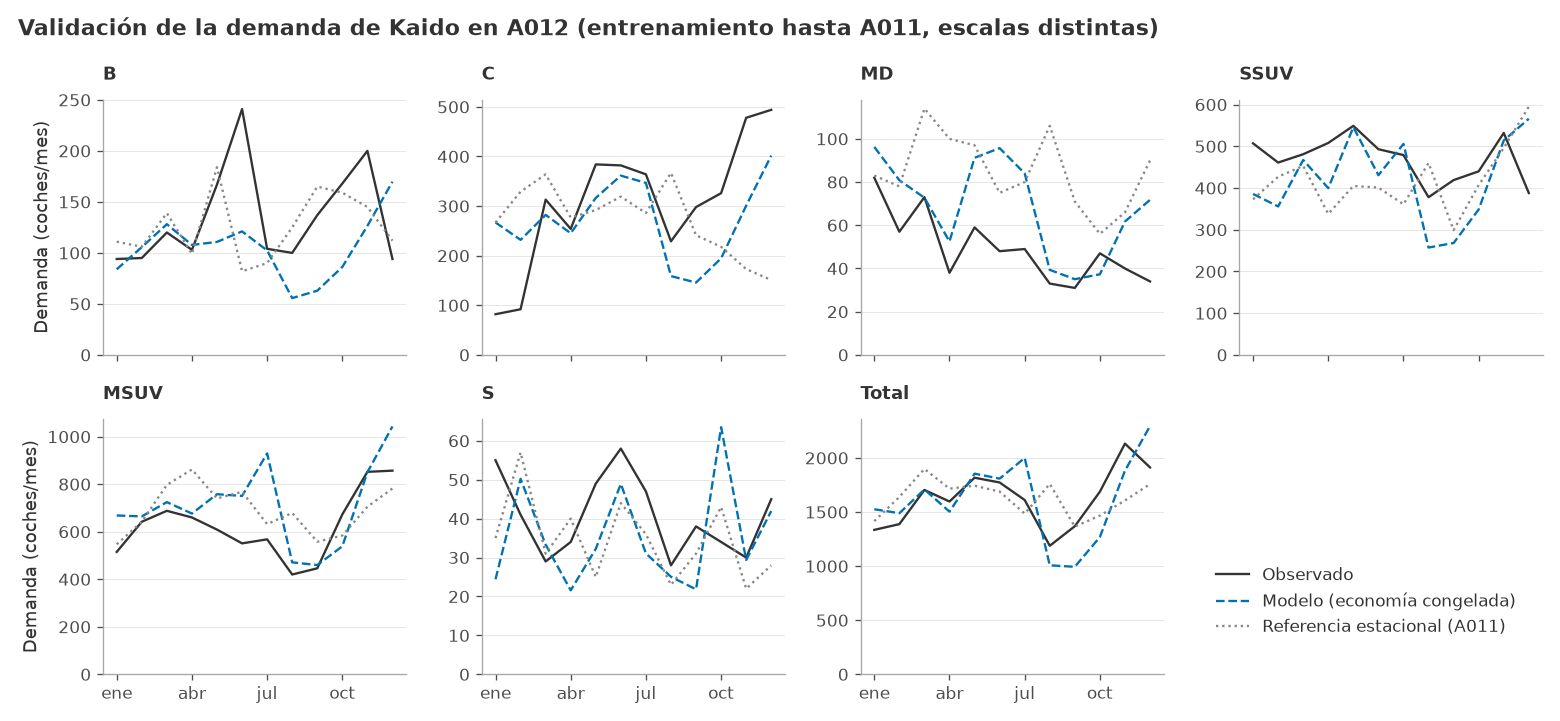

In [12]:
fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
meses = observado.index
previsto = previsiones["Modelo, economía congelada"]["demanda"]
total_obs = observado[SEG_VALIDACION].sum(axis=1)
for eje, segmento in zip(ejes.flat, orden):
    if segmento == "Total":
        o, m, r = total_obs, previsto[SEG_VALIDACION].sum(axis=1), \
            referencia[SEG_VALIDACION].sum(axis=1)
    else:
        o, m, r = observado[segmento], previsto[segmento], referencia[segmento]
    eje.plot(meses, o, color=GRIS_OSCURO, ls="-", lw=1.4, label="Observado")
    eje.plot(meses, m, color=AZUL, ls="--", lw=1.4, label="Modelo (economía congelada)")
    eje.plot(meses, r, color=GRIS_MEDIO, ls=":", lw=1.4, label="Referencia estacional (A011)")
    eje.set_title(segmento, fontsize=11)
    eje.set_ylim(bottom=0)
    eje.set_xticks(meses[::3], ["ene", "abr", "jul", "oct"])
ejes.flat[-1].axis("off")
for eje in ejes[:, 0]:
    eje.set_ylabel("Demanda (coches/mes)")
fig.legend(*ejes.flat[0].get_legend_handles_labels(), loc="lower right",
           bbox_to_anchor=(0.98, 0.1), frameon=False)
fig.suptitle("Validación de la demanda de Kaido en A012 (entrenamiento hasta A011, "
             "escalas distintas)", x=0.01, ha="left", fontweight="bold")
guardar_figura(fig, "validacion_demanda_a012_segmento")
plt.show()

Fuente: `mercado_mensual.csv` y `ventas_kaido_mensuales.csv`, A003–A012. En el total de los seis segmentos el error mensual es del 12,6 % (economía congelada) y del 12,0 % (real), igual que la referencia (12,3 %) y sin sesgo apreciable. Saber la economía real casi no cambia el resultado: la confianza aporta poco en un año. Por segmento, el modelo mejora a la referencia en C (29,6 % frente a 45,5 %), MD (41,8 % frente a 71,9 %) y SSUV, y empeora en B (34,6 % frente a 23,2 %) y algo en S. MD queda sobreprevista un 38 %: el modelo no capta su declive estructural. El mercado se prevé peor que con la referencia (17,1 % frente a 9,9 % en total), así que la mejora o igualdad en demanda procede sobre todo de la cuota media, que suaviza el ruido de un año concreto.

### 2.3. Robustez y rango de error

Una sola validación es poca información. Se repite entrenando hasta A009, A010 y A011, y se validan A010, A011 y A012 con la economía congelada. Los 36 errores mensuales de cada segmento (`log(previsión / observado)`) dan el rango de error que se usará como banda de la previsión: es la variabilidad observada en la validación, no una probabilidad.

In [13]:
ORIGENES = [108, 120, 132]  # entrenar hasta A009, A010 y A011
filas, errores = [], []
for origen in ORIGENES:
    obs = mat["demanda"].loc[origen + 1: origen + 12]
    p = demanda.prever_demanda(dd, mat, origen)
    ref = demanda.referencia_estacional(mat["demanda"], origen)
    anio = f"A{origen // 12 + 1:03d}"
    obs_m = mat["mercado"].loc[origen + 1: origen + 12]
    ref_m = demanda.referencia_estacional(mat["mercado"], origen)
    for nivel, prevs, observados in [
            ("demanda", {"Modelo": p["demanda"], "Referencia estacional": ref}, obs),
            ("mercado", {"Modelo": p["mercado"], "Referencia estacional": ref_m},
             obs_m)]:
        for variante, prev in prevs.items():
            filas.append(demanda.metricas(prev, observados, SEG_VALIDACION)
                         .assign(variante=variante, anio_validado=anio, nivel=nivel))
    prev6 = p["demanda"][SEG_VALIDACION]
    log_error = np.log(prev6 / obs[SEG_VALIDACION]).replace([np.inf, -np.inf], np.nan)
    log_error["Total"] = np.log(prev6.sum(axis=1) / obs[SEG_VALIDACION].sum(axis=1))
    errores.append(log_error.assign(anio_validado=anio))
origenes = pd.concat(filas, ignore_index=True)
origenes.to_csv(TABLAS / "validacion_origenes_metricas.csv", index=False)


def resumen_origenes(nivel):
    t = origenes[origenes["nivel"] == nivel]
    resumen = t.groupby(["segmento", "variante"])["mae_pct"].mean().unstack("variante")
    victorias = (t.pivot_table(index=["segmento", "anio_validado"],
                               columns="variante", values="mae_pct")
                 .assign(gana=lambda d: d["Modelo"] < d["Referencia estacional"])
                 .groupby("segmento")["gana"].sum())
    resumen["validaciones_ganadas_por_el_modelo"] = victorias.astype(int).astype(str) + " de 3"
    return resumen.reindex(orden)


for nivel, titulo in [("demanda", "Demanda de Kaido"), ("mercado", "Mercado del segmento")]:
    print(f"{titulo}: MAE sobre la media mensual, media de las validaciones de "
          "A010, A011 y A012")
    display(formato_es(resumen_origenes(nivel),
                       porcentajes=["Modelo", "Referencia estacional"]))

Demanda de Kaido: MAE sobre la media mensual, media de las validaciones de A010, A011 y A012


variante,Modelo,Referencia estacional,validaciones_ganadas_por_el_modelo
segmento,,,
B,"34,8 %","26,1 %",0 de 3
C,"23,8 %","31,3 %",3 de 3
MD,"35,3 %","45,5 %",2 de 3
SSUV,"18,5 %","22,3 %",3 de 3
MSUV,"19,1 %","28,1 %",3 de 3
S,"42,9 %","39,3 %",1 de 3
Total,"13,4 %","15,6 %",2 de 3


Mercado del segmento: MAE sobre la media mensual, media de las validaciones de A010, A011 y A012


variante,Modelo,Referencia estacional,validaciones_ganadas_por_el_modelo
segmento,,,
B,"12,1 %","9,1 %",0 de 3
C,"15,7 %","12,8 %",0 de 3
MD,"28,9 %","30,7 %",2 de 3
SSUV,"22,5 %","22,1 %",2 de 3
MSUV,"16,1 %","19,0 %",3 de 3
S,"37,6 %","33,0 %",0 de 3
Total,"11,9 %","10,2 %",2 de 3


En la demanda total el modelo supera a la referencia en dos de las tres validaciones (13,4 % frente a 15,6 % de error medio). Gana siempre en C, SSUV y MSUV y pierde siempre en B. En el mercado, en cambio, no mejora: 11,9 % frente a 10,2 % en total. Se concluye que el modelo de mercado no aporta precisión adicional sobre la referencia estacional, pero tampoco la empeora de forma clara en la demanda total, y que su valor es incorporar sucesos y economía, que los escenarios de la sección 9.2 necesitan como palancas. Las previsiones de B y S son poco fiables (errores del 35–43 %): son segmentos pequeños y volátiles, con 1.600 y 500 coches al año.

### 2.4. Previsión de A013

Se vuelve a estimar con todos los datos hasta A012 y se prevé A013 con el calendario de `calendario_mensual_a013.csv`. Supuestos del escenario central: la caída tras el adelanto dura tres meses (enero–marzo), no hay plan público ni subida del IVA, y la confianza se mantiene en su valor de diciembre de A012 (77,7, frente a 96,7 de media en enero–julio). La cuota de CSUV es la de septiembre y octubre de A012. La banda es el rango de error de validación (P10–P90) sobre cada mes; un rango anual exige la simulación de la fase 4.

In [14]:
BASE = demanda.prever_demanda(dd, mat, demanda.T_FIN_DATOS, demanda.EVENTOS_CENTRAL)
errores = pd.concat(errores)[orden]
rango = errores.quantile([0.10, 0.90]).T.rename(columns={0.10: "p10", 0.90: "p90"})
rango.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "error_log_validacion_p10_p90.csv", index=False)

calendario = dd["calendario"].set_index("t")
prevision = (
    BASE["demanda"].stack().rename("demanda_central").reset_index()
    .merge(BASE["mercado"].stack().rename("mercado").reset_index(),
           on=["t", "segmento"])
)
prevision["cuota"] = prevision["segmento"].map(BASE["cuota"])
# Si el error es previsión/observado = exp(e), el observado es previsión/exp(e).
prevision["demanda_p10"] = prevision["demanda_central"] / np.exp(
    prevision["segmento"].map(rango["p90"]).fillna(rango.loc[SEG_VALIDACION, "p90"].mean()))
prevision["demanda_p90"] = prevision["demanda_central"] / np.exp(
    prevision["segmento"].map(rango["p10"]).fillna(rango.loc[SEG_VALIDACION, "p10"].mean()))
prevision.insert(1, "periodo", prevision["t"].map(calendario["periodo"]))
prevision["segmento"] = pd.Categorical(prevision["segmento"], datos.SEGMENTOS, ordered=True)
prevision = prevision.sort_values(["segmento", "t"])
prevision.to_csv(TABLAS / "prevision_demanda_a013.csv", index=False)

plan = BASE["demanda"].copy()
plan["Total"] = plan.sum(axis=1)
plan.index = [f"{(t - 1) % 12 + 1:02d}" for t in plan.index]
plan.loc["Año A013"] = plan.sum()
a012 = mat["demanda"].loc[133:144].sum()
anual = pd.DataFrame({
    "demanda_a012": a012,
    "demanda_a013": BASE["demanda"].sum(),
    "cuota_a013_pct": BASE["cuota"],
})
anual.loc["Total"] = [a012.sum(), BASE["demanda"].sum().sum(), np.nan]
anual["variacion_pct"] = anual["demanda_a013"] / anual["demanda_a012"] - 1
anual.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "prevision_anual_a013_vs_a012.csv", index=False)
print("Demanda de Kaido prevista (central), coches; A012 es lo observado")
display(formato_es(anual, porcentajes=["cuota_a013_pct", "variacion_pct"]))
print("Plan mensual de demanda prevista A013 (coches), por mes")
formato_es(plan[datos.SEGMENTOS + ["Total"]].round(0))

Demanda de Kaido prevista (central), coches; A012 es lo observado


,demanda_a012,demanda_a013,cuota_a013_pct,variacion_pct
B,1.623,1.256,"0,7 %","-22,6 %"
C,3.696,2.586,"1,9 %","-30,0 %"
MD,591,475,"3,0 %","-19,6 %"
SSUV,5.635,4.888,"3,8 %","-13,3 %"
CSUV,1.192,2.768,"1,9 %","132,2 %"
MSUV,7.481,6.088,"4,5 %","-18,6 %"
S,488,410,"60,6 %","-15,9 %"
Total,20.706,18.471,—,"-10,8 %"


Plan mensual de demanda prevista A013 (coches), por mes


segmento,B,C,MD,SSUV,CSUV,MSUV,S,Total
01,99,182,30,292,194,344,37,1.178
02,97,198,32,414,263,391,25,1.420
03,132,238,35,471,306,560,49,1.791
04,133,294,48,524,266,552,46,1.863
05,120,247,39,413,261,557,38,1.675
06,155,301,55,640,293,648,50,2.142
07,126,229,39,473,246,579,39,1.731
08,77,144,22,255,160,335,20,1.013
09,78,193,45,344,188,461,21,1.331
10,81,187,54,340,201,544,21,1.429


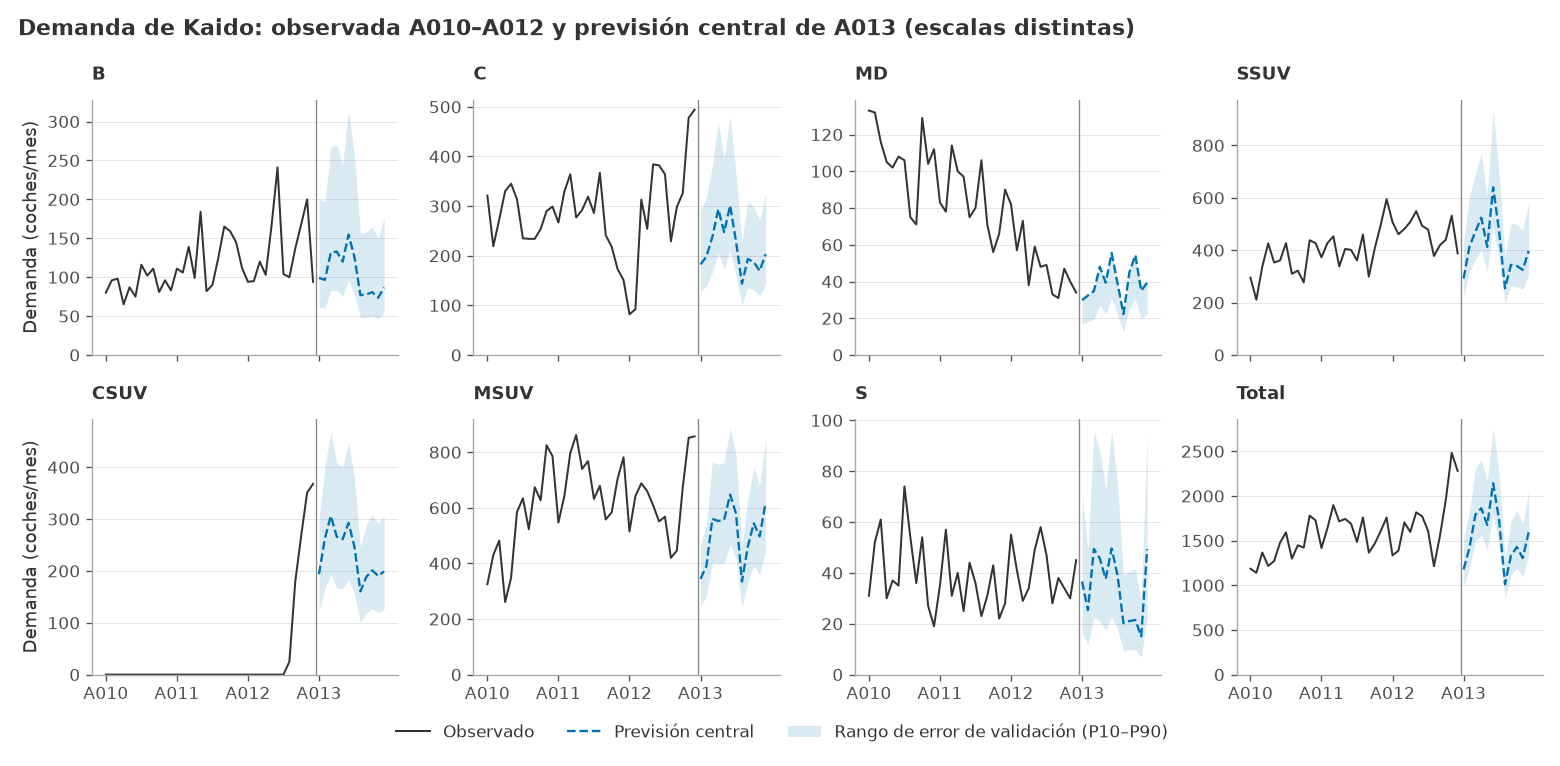

In [15]:
historia = mat["demanda"].loc[109:144]
fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for eje, segmento in zip(ejes.flat, datos.SEGMENTOS + ["Total"]):
    p = prevision if segmento == "Total" else prevision[prevision["segmento"] == segmento]
    if segmento == "Total":
        h = historia.sum(axis=1)
        agr = p.groupby("t")[["demanda_central", "demanda_p10", "demanda_p90"]].sum()
        p10 = agr["demanda_central"] / np.exp(rango.loc["Total", "p90"])
        p90 = agr["demanda_central"] / np.exp(rango.loc["Total", "p10"])
        central = agr["demanda_central"]
    else:
        h = historia[segmento]
        central, p10, p90 = (p.set_index("t")[c] for c in
                             ["demanda_central", "demanda_p10", "demanda_p90"])
    eje.plot(h.index, h, color=GRIS_OSCURO, lw=1.2, label="Observado")
    eje.plot(central.index, central, color=AZUL, ls="--", lw=1.4, label="Previsión central")
    eje.fill_between(central.index, p10, p90, color=AZUL, alpha=0.15, lw=0,
                     label="Rango de error de validación (P10–P90)")
    eje.axvline(144.5, color=GRIS_MEDIO, lw=0.8)
    eje.set_title(segmento, fontsize=11)
    eje.set_ylim(bottom=0)
    eje.set_xticks([109, 121, 133, 145], ["A010", "A011", "A012", "A013"])
for eje in ejes[:, 0]:
    eje.set_ylabel("Demanda (coches/mes)")
fig.legend(*ejes.flat[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False)
fig.suptitle("Demanda de Kaido: observada A010–A012 y previsión central de A013 "
             "(escalas distintas)", x=0.01, ha="left", fontweight="bold")
guardar_figura(fig, "demanda_prevision_a013_segmento")
plt.show()

Fuente: modelo ajustado hasta A012; `demanda_a012` es lo observado, con compras adelantadas en noviembre y diciembre. Se estima una demanda de unos 18.500 coches en A013, un 10,8 % menos que en A012. Sin CSUV, la caída es del 19,5 % (de 19.500 a 15.700 coches). El mercado de los siete segmentos se estima un 16 % menor. Tres factores explican la caída: A013 no repite el adelanto de fin de A012, empieza con la caída posterior y la confianza del consumidor cayó 19 puntos entre julio y diciembre de A012. CSUV es el único segmento que crece, porque A012 solo recoge cinco meses de venta. La previsión de 2.800 coches de CSUV depende de una cuota de 1,9 % (septiembre–octubre) y es la más incierta. Estas cifras son una demanda sin restricción de stock: el simulador la convertirá en ventas.

In [16]:
conf_a012 = dd["economia"].loc[dd["economia"]["anio"] == "A012"]
conf_ene_jul = conf_a012.loc[conf_a012["mes"] <= 7, "confianza_consumidor"].mean()
variantes = {
    "Central": {},
    "Sin caída tras el adelanto": {"eventos_a013": {}},
    "Confianza vuelve a la media de ene–jul A012": {"confianza_a013": conf_ene_jul},
    "Cuota sin meses con falta de stock": {"excluir_falta_stock": True},
}
filas = []
for nombre, extra in variantes.items():
    args = {"eventos_a013": demanda.EVENTOS_CENTRAL, **extra}
    p = demanda.prever_demanda(dd, mat, demanda.T_FIN_DATOS, **args)
    total = p["demanda"].sum()
    filas.append({"variante": nombre, **total.to_dict(),
                  "Total": total.sum()})
sensibilidad = pd.DataFrame(filas).set_index("variante")
sensibilidad["variacion_total_vs_central_pct"] = (
    sensibilidad["Total"] / sensibilidad.loc["Central", "Total"] - 1)
sensibilidad.reset_index().to_csv(
    TABLAS / "sensibilidad_prevision_a013.csv", index=False)
print(f"Confianza media ene–jul A012: {conf_ene_jul:.1f}; "
      f"último valor conocido (dic A012): "
      f"{dd['economia'].set_index('t').loc[144, 'confianza_consumidor']:.1f}")
formato_es(sensibilidad, porcentajes=["variacion_total_vs_central_pct"])

Confianza media ene–jul A012: 96.7; último valor conocido (dic A012): 77.7


,B,C,MD,SSUV,CSUV,MSUV,S,Total,variacion_total_vs_central_pct
variante,,,,,,,,,
Central,1.256,2.586,475,4.888,2.768,6.088,410,18.471,"0,0 %"
Sin caída tras el adelanto,1.282,2.635,483,4.980,2.828,6.190,419,18.817,"1,9 %"
Confianza vuelve a la media de ene–jul A012,1.404,2.900,535,5.478,3.087,6.851,458,20.713,"12,1 %"
Cuota sin meses con falta de stock,1.217,2.765,475,4.888,2.768,6.088,410,18.611,"0,8 %"


**Respuesta a la pregunta 2.** Se estima que la demanda de Kaido en A013 será de unos 18.500 coches en el escenario central (un 10,8 % menos que lo observado en A012; un 19,5 % menos sin CSUV). El error mensual esperado es de un 12–15 % en el total y de un 18–43 % por segmento, mayor en B, S y MD. La sensibilidad más importante es la confianza: si volviera a su media de enero–julio de A012, la previsión subiría un 12 %; el resto de variantes mueve menos de un 2 %.

**Limitaciones.**

- El modelo de mercado no mejora de forma clara a la referencia estacional; sirve como herramienta para los escenarios, no como mejora de precisión demostrada.
- El efecto de la confianza se estima con pocos ciclos económicos, y los efectos del adelanto y de la caída con dos episodios.
- La validación supone conocidos los sucesos del año validado, y los orígenes A009–A011 solo cubren un periodo de recuperación.
- No se modelan las renovaciones de gama: son marcas puntuales (5–8 por segmento) y no se identifica un efecto estable sobre la cuota.
- La cuota de CSUV es un supuesto sin validación posible.
- La demanda prevista es sin restricción de stock; las automatriculaciones se añadirán en el simulador.

## 3. Simulación determinista del año A013

**Pregunta.** Si la demanda de A013 es la prevista en la sección 2 y se sigue la regla de planificación de la sección 7 del enunciado, ¿qué llegadas, stock, antigüedad y costes resultan? Es el paso previo a la pregunta 4 (producción y stock) y a los escenarios con incertidumbre de la fase 4.

**Método.** Cada segmento se simula mes a mes con `src/simulacion.py`: `V = min(D, S + L)` y `S' = S + L − V`, con el stock por cohortes de entrada y venta FIFO (primero el más antiguo). La llegada de dentro de tres meses se decide con `L = max(0, D̂ + SS − Ŝ)`, redondeada hacia arriba a coches enteros, y `SS = z · σ · √3`. Con la demanda real igual a la prevista, revisar el plan cada mes no lo cambia, así que se calcula una vez a final de A012.

### 3.1. Supuestos

| Decisión | Supuesto | Justificación | Efecto esperado |
|---|---|---|---|
| Stock inicial | El de `stock_red_mensual.csv` a fin de A012, por tramos de antigüedad | Es el dato observado; el balance original lo cumple (sección 1.2) | Punto de partida real de la red |
| Edades iniciales | Uniformes dentro de cada tramo, en bloques de 30 días; más de 180 días, un solo bloque | No se conoce la edad exacta | Ligera imprecisión del coste de enero–junio |
| Llegadas de enero y febrero | Media mensual de la facturación a la red de julio–diciembre de A012 (agosto–diciembre en CSUV) | Los datos no dicen qué viene en camino (sección 7.2) y se debe estimar; es el ritmo reciente de la marca | Es el supuesto más influyente; ver sensibilidad |
| Stock de seguridad | `z = 1,28`; σ = desviación típica del error relativo de validación (sección 2.3) × demanda prevista del mes. CSUV usa la media de los demás segmentos | Cubre nueve de cada diez meses (sección 7.3); el nivel de servicio por segmento queda para la fase 4 | En un año determinista el colchón no evita ninguna venta perdida: solo añade stock |
| Pedidos | Hacia arriba a coche entero; el stock proyectado no baja de cero | Regla explícita del simulador | Nunca se pide por debajo del objetivo |
| Tiempo | Año de 365 días; llegadas y ventas a mitad de mes de media | Aproximación de días dentro de cada mes | Un coche que llega y se vende el mismo mes no genera coste |
| Coste del stock | 2 €/coche/día hasta 180 días de antigüedad total, contando los días de A012 de los coches ya en la red; sin intereses del concesionario | Sección 2.4 | Coste de A013 solo |
| VM y CVP | Beneficio bruto de la tarifa de A013 sin prima de CO2 y VM real de A011–A012 según los días del coche en la red | `catalogo_segmentos.csv` | CVP = bruto − VM |
| Faltas de stock | No hay transfers: lo que no se puede servir son ventas perdidas. Se informa su CVP y el coste del transfer alternativo (20 % del beneficio bruto) | Disponibilidad y plazo del transfer pendientes (guía, sección 7) | Las ventas perdidas no restan beneficio |
| Automatriculaciones | No se simulan: la demanda es la de clientes | Su volumen es decisión de la marca y no hay una regla en el caso | Subestima las salidas de stock y la producción necesaria (hasta ~11 % de las matriculaciones en A003–A012) |
| Fin de año | El stock a 31 de diciembre se informa sin valorarlo; no se simulan pedidos para A014 | Pendiente de decisión (guía, sección 7) | El último trimestre de llegadas puede ser algo alto o bajo según el plan de A014 |

In [17]:
from src import simulacion

# Comprobación del código con el ejemplo de la tabla 3 del enunciado (MSUV, coches).
ss_ejemplo = 1.28 * 100 * np.sqrt(3)
stock_proyectado = 536 + 700 + 700 - 550 - 600
pedido = simulacion.llegada_a_pedir(stock_proyectado, 850, ss_ejemplo)
print(f"Stock proyectado a fin de febrero: {stock_proyectado}")
print(f"Stock de seguridad: {ss_ejemplo:.1f}")
print(f"Llegada que hay que pedir para marzo: {pedido} (tabla 3: 286)")
assert pedido == 286

Stock proyectado a fin de febrero: 786
Stock de seguridad: 221.7
Llegada que hay que pedir para marzo: 286 (tabla 3: 286)


In [18]:
DEM = BASE["demanda"].reset_index(drop=True)  # mes 0..11 de A013
cohortes = simulacion.stock_inicial(dd)
economia = simulacion.economia_segmentos(dd)
stock_a012 = pd.Series({s: c["unidades"].sum() for s, c in cohortes.items()})
en_camino = simulacion.llegadas_iniciales(dd)

# σ relativa: desviación típica del error log(previsión/observado) de la validación
# (sección 2.3). CSUV no tiene validación: usa la media de los seis segmentos.
sd_rel = errores[orden].std()
sd_rel["CSUV"] = sd_rel[SEG_VALIDACION].mean()
sigma = DEM * sd_rel[datos.SEGMENTOS]
sigma_tabla = sd_rel[datos.SEGMENTOS].rename("sd_relativa_error_mensual")
sigma_tabla.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "sigma_relativa_validacion.csv", index=False)

stock_dic = dd["stock"].loc[dd["stock"]["periodo"] == "A0121201"].set_index("segmento")
estado = pd.DataFrame({
    "stock_dic_a012": stock_dic["stock_total"],
    "con_mas_90_dias": stock_dic["s_91_180"] + stock_dic["s_mas_180"],
    "llegadas_ene_feb_supuestas": en_camino.iloc[0],
    "demanda_ene_feb_prevista": DEM.iloc[:2].sum(),
    "sd_relativa_error": sd_rel,
}).reindex(datos.SEGMENTOS)
estado["cobertura_inicial_meses"] = (
    (estado["stock_dic_a012"] + 2 * estado["llegadas_ene_feb_supuestas"])
    / (estado["demanda_ene_feb_prevista"] / 2))
estado.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "estado_inicial_a013.csv", index=False)
print("Punto de partida de A013, coches (cobertura: stock de diciembre más llegadas de "
      "enero y febrero entre la demanda media prevista de enero y febrero, en meses)")
formato_es(estado, decimales=0, porcentajes=["sd_relativa_error"]).format(
    "{:.1f}", subset=["cobertura_inicial_meses"], decimal=",")

Punto de partida de A013, coches (cobertura: stock de diciembre más llegadas de enero y febrero entre la demanda media prevista de enero y febrero, en meses)


,stock_dic_a012,con_mas_90_dias,llegadas_ene_feb_supuestas,demanda_ene_feb_prevista,sd_relativa_error,cobertura_inicial_meses
B,97,0,124,196,"44,6 %","3,5"
C,1.107,479,454,381,"38,8 %","10,6"
MD,125,108,43,62,"24,4 %","6,8"
SSUV,0,0,390,706,"25,6 %","2,2"
CSUV,1.011,327,489,456,"35,5 %","8,7"
MSUV,536,101,576,735,"26,7 %","4,6"
S,1,1,34,62,"53,1 %","2,2"


Al empezar A013 la red está muy descompensada. C tiene 1.107 coches y CSUV 1.011, con una cobertura inicial de 10,6 y 8,7 meses, y el 43 % y el 32 % de su stock con más de 90 días. SSUV está sin stock y S tiene un coche. Con las llegadas en camino supuestas, MSUV y B quedan entre 3,5 y 4,6 meses. Estas llegadas de enero y febrero (2.110 coches cada mes) son muy superiores a la demanda prevista (1.178 y 1.420), porque el ritmo de facturación de A012 estaba pensado para una demanda mayor. Las σ relativas del 24–53 % son las de la validación; B y S son las más inciertas.

In [19]:
Z = simulacion.Z_DEFECTO
ss = simulacion.stock_seguridad(sigma, Z)
plan = simulacion.planificar_llegadas(DEM, stock_a012, en_camino, ss)

plan_largo = plan.stack().rename("llegadas").reset_index()
plan_largo.columns = ["mes", "segmento", "llegadas"]
plan_largo["mes"] += 1
plan_largo.to_csv(TABLAS / "plan_llegadas_central_a013.csv", index=False)

vista = plan.copy()
vista["Total"] = vista.sum(axis=1)
vista.index = [f"{m + 1:02d}" for m in vista.index]
vista.loc["Año A013"] = vista.sum()
print(f"Llegadas planificadas (coches), escenario central, z = {Z}. "
      "Enero y febrero son las llegadas en camino supuestas")
formato_es(vista[datos.SEGMENTOS + ["Total"]])

Llegadas planificadas (coches), escenario central, z = 1.28. Enero y febrero son las llegadas en camino supuestas


,B,C,MD,SSUV,CSUV,MSUV,S,Total
01,124,454,43,390,489,576,34,2.110
02,124,454,43,390,489,576,34,2.110
03,113,0,0,665,0,0,99,877
04,134,0,0,554,0,487,42,1.217
05,107,0,0,350,0,560,28,1.045
06,189,0,59,769,0,701,63,1.781
07,97,0,30,379,34,539,27,1.106
08,29,0,14,130,93,190,0,456
09,79,178,57,395,210,536,20,1.475
10,83,182,59,337,211,593,22,1.487


Con tanto stock y llegadas en camino, la regla no pide nada en C hasta septiembre, en CSUV hasta julio y en MD hasta junio, y concentra las llegadas en SSUV, MSUV y S, donde falta stock. El plan tiene 16.684 llegadas en el año, 1.785 menos que las ventas, porque se consume el stock inicial. Se parece a lo que anticipa la tabla 3: lo que ya está en camino hace caer la producción del primer mes que se puede tocar (marzo cae de 2.110 a 877 coches). La caída de agosto se debe a la menor demanda prevista de ese mes.

In [20]:
mensual = simulacion.simular_anio(DEM, plan, cohortes, economia)
mensual.to_csv(TABLAS / "simulacion_central_mensual_a013.csv", index=False)


def resumen_simulacion(m, cohortes):
    g = m.groupby("segmento", sort=False)
    r = pd.DataFrame({
        "ventas": g["ventas"].sum(),
        "ventas_perdidas": g["perdidas"].sum(),
        "fabricados": g["llegadas"].sum(),
        "stock_medio": g["stock_fin"].mean(),
        "stock_fin_a013": g["stock_fin"].last(),
        "con_mas_90_dias_fin": g["stock_91_180"].last() + g["stock_mas_180"].last(),
        "coste_stock_eur": g["coste_stock"].sum(),
        "vm_eur": g["vm"].sum(),
        "cvp_eur": g["cvp"].sum(),
        "cvp_perdido_eur": g["cvp_perdido"].sum(),
        "transfer_alternativo_eur": g["coste_transfer_alternativo"].sum(),
    }).reindex(datos.SEGMENTOS)
    r["cobertura_media_meses"] = r["stock_medio"] / (r["ventas"] / 12)
    r["resultado_eur"] = r["cvp_eur"] - r["coste_stock_eur"]
    total = r.sum()
    total["cobertura_media_meses"] = total["stock_medio"] / (total["ventas"] / 12)
    r.loc["Total"] = total
    return r


resumen = resumen_simulacion(mensual, cohortes)
resumen.rename_axis("segmento").reset_index().to_csv(
    TABLAS / "simulacion_central_resumen_a013.csv", index=False)
print("Año A013, escenario central determinista (demanda real = demanda prevista). "
      "Coches y euros del año; stock medio = media de los fines de mes")
display(formato_es(resumen[["ventas", "ventas_perdidas", "fabricados", "stock_medio",
                            "con_mas_90_dias_fin"]]).format(
    "{:.1f}", subset=["ventas_perdidas"], decimal=","))
formato_es(resumen[["coste_stock_eur", "vm_eur", "cvp_eur", "resultado_eur",
                    "cvp_perdido_eur", "cobertura_media_meses"]]).format(
    "{:.1f}", subset=["cobertura_media_meses"], decimal=",")

Año A013, escenario central determinista (demanda real = demanda prevista). Coches y euros del año; stock medio = media de los fines de mes


,ventas,ventas_perdidas,fabricados,stock_medio,con_mas_90_dias_fin
segmento,,,,,
B,1.256,"0,0",1.246,110,0
C,2.586,"0,0",1.654,673,0
MD,475,"0,0",372,54,0
SSUV,4.888,"0,0",5.114,213,0
CSUV,2.768,"0,0",1.914,589,0
MSUV,6.088,"0,0",5.918,413,0
S,409,"1,6",466,35,0
Total,18.469,"1,6",16.684,2.088,0


,coste_stock_eur,vm_eur,cvp_eur,resultado_eur,cvp_perdido_eur,cobertura_media_meses
segmento,,,,,,
B,80.824,2.157.910,156.128,75.303,0,"1,1"
C,490.269,6.854.413,2.642.379,2.152.110,0,"3,1"
MD,36.327,1.731.557,1.858.981,1.822.654,0,"1,4"
SSUV,148.983,9.657.839,13.963.789,13.814.805,0,"0,5"
CSUV,451.349,5.434.950,8.302.185,7.850.836,0,"2,6"
MSUV,303.457,11.603.425,35.772.451,35.468.994,0,"0,8"
S,24.188,772.956,2.022.519,1.998.331,8.080,"1,0"
Total,1.535.398,38.213.050,64.718.431,63.183.033,8.080,"1,4"


In [21]:
balance = simulacion.comprobar_balance(mensual, cohortes)
print(f"Balance de unidades correcto en {balance['correcto'].sum()} de {len(balance)} "
      "segmentos")
display(formato_es(balance.set_index("segmento")[[
    "balance_mensual", "balance_anual", "continuidad_stock", "suma_tramos",
    "ventas_mas_perdidas_menos_demanda", "stock_minimo"]], decimales=6))

# Casos límite con cuentas hechas a mano (un solo segmento, MSUV).
eco = economia.loc["MSUV"]
sin_demanda = pd.Series(0.0, index=range(12))
ninguna = pd.Series(0, index=range(12))
un_bloque = pd.DataFrame({"entrada": [-15.0], "unidades": [10.0]})
parado = simulacion.simular_segmento("MSUV", sin_demanda, ninguna, un_bloque, eco)
# Diez coches de 15 días sin venderse: 2 €/día hasta los 180 días, es decir 165 días.
assert abs(parado["coste_stock"].sum() - 10 * 2 * 165) < 1e-6
assert parado["stock_fin"].iloc[-1] == 10 and parado["stock_mas_180"].iloc[-1] == 10

dos_edades = pd.DataFrame({"entrada": [-200.0, -15.0], "unidades": [5.0, 5.0]})
demanda_5 = pd.Series([5.0] + [0.0] * 11)
fifo = simulacion.simular_segmento("MSUV", demanda_5, ninguna, dos_edades, eco)
# FIFO: se venden los cinco coches de 200 días y quedan los de 15.
assert fifo["stock_mas_180"].iloc[0] == 0 and fifo["stock_0_90"].iloc[0] == 5
assert abs(fifo["vm"].iloc[0] - 5 * eco["vm_mas_180"]) < 1e-6

escasez = simulacion.simular_segmento(
    "MSUV", pd.Series([20.0] + [0.0] * 11), ninguna, un_bloque, eco)
assert escasez["ventas"].iloc[0] == 10 and escasez["perdidas"].iloc[0] == 10
print("Casos límite correctos: coste de un coche parado, FIFO y falta de stock")

Balance de unidades correcto en 7 de 7 segmentos


,balance_mensual,balance_anual,continuidad_stock,suma_tramos,ventas_mas_perdidas_menos_demanda,stock_minimo
segmento,,,,,,
B,"0,000000","0,000000","0,000000","0,000000","0,000000","73,513810"
C,"0,000000","0,000000","0,000000","0,000000","0,000000","146,755290"
MD,"0,000000","0,000000","0,000000","0,000000","0,000000","12,897783"
SSUV,"0,000000","0,000000","0,000000","0,000000","0,000000","74,012326"
CSUV,"0,000000","0,000000","0,000000","0,000000","0,000000","127,090562"
MSUV,"0,000000","0,000000","0,000000","0,000000","0,000000","198,445511"
S,"0,000000","0,000000","0,000000","0,000000","0,000000","0,000000"


Casos límite correctos: coste de un coche parado, FIFO y falta de stock


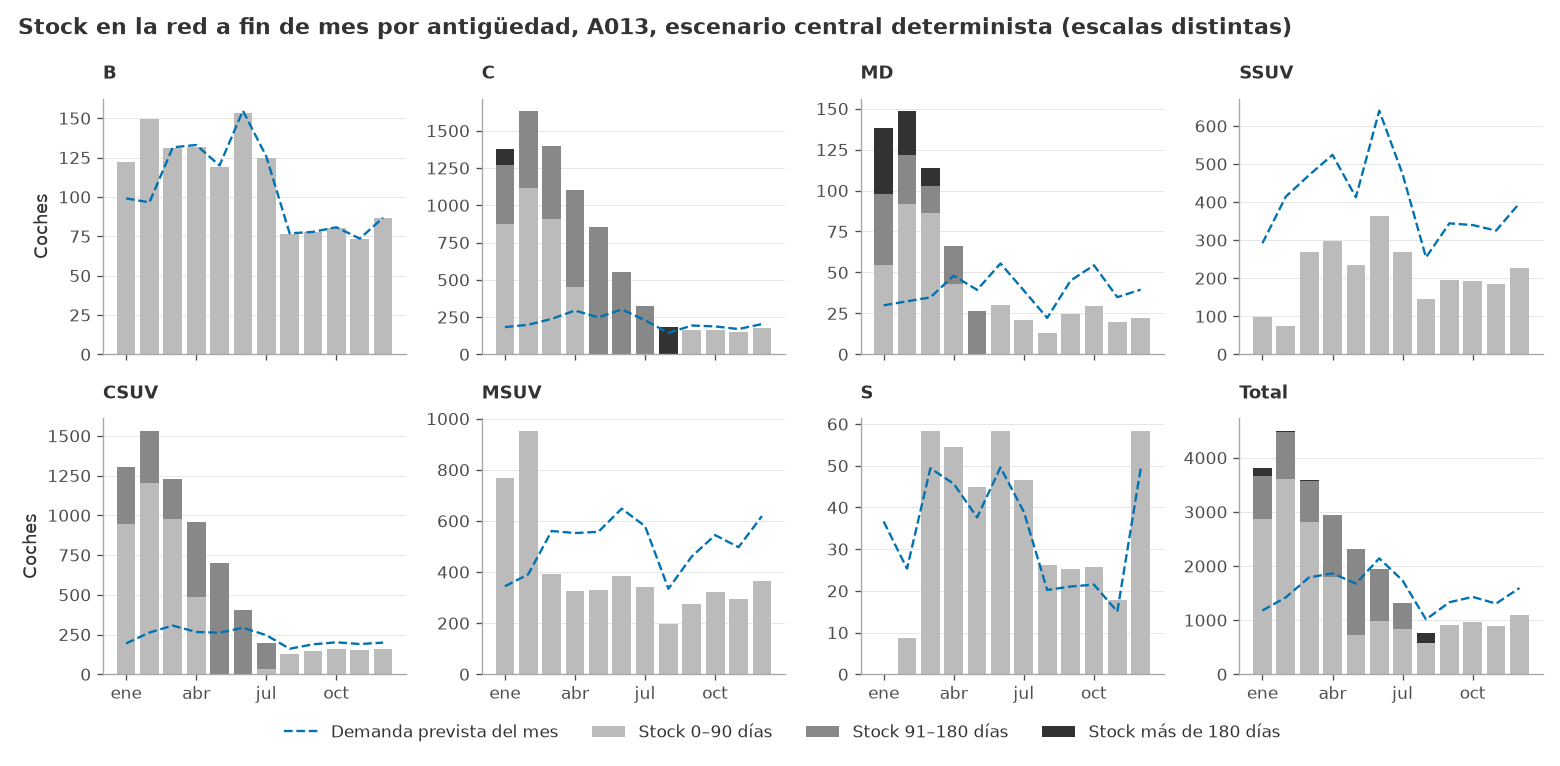

In [22]:
fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
colores = {"stock_0_90": "#BBBBBB", "stock_91_180": GRIS_MEDIO, "stock_mas_180": GRIS_OSCURO}
etiquetas = {"stock_0_90": "Stock 0–90 días", "stock_91_180": "Stock 91–180 días",
             "stock_mas_180": "Stock más de 180 días"}
for eje, segmento in zip(ejes.flat, datos.SEGMENTOS + ["Total"]):
    m = mensual if segmento == "Total" else mensual[mensual["segmento"] == segmento]
    m = m.groupby("mes")[["stock_0_90", "stock_91_180", "stock_mas_180", "demanda"]].sum()
    base = np.zeros(len(m))
    for columna in colores:
        eje.bar(m.index, m[columna], bottom=base, color=colores[columna],
                label=etiquetas[columna], width=0.8)
        base += m[columna].to_numpy()
    eje.plot(m.index, m["demanda"], color=AZUL, ls="--", lw=1.4,
             label="Demanda prevista del mes")
    eje.set_ylim(0, 1.05 * max(base.max(), m["demanda"].max()))
    eje.set_title(segmento, fontsize=11)
    eje.set_xticks([1, 4, 7, 10], ["ene", "abr", "jul", "oct"])
for eje in ejes[:, 0]:
    eje.set_ylabel("Coches")
fig.legend(*ejes.flat[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(0.5, 0.02), ncol=4, frameon=False)
fig.suptitle("Stock en la red a fin de mes por antigüedad, A013, escenario central "
             "determinista (escalas distintas)", x=0.01, ha="left", fontweight="bold")
guardar_figura(fig, "stock_antiguedad_central_a013")
plt.show()

Fuente: simulación determinista con el plan anterior. Se venden 18.469 coches (se pierden 1,6 en S en enero, porque solo había un coche y llegan 34 para una demanda de 37), con un stock medio de 2.088 coches (1,4 meses de cobertura). El stock de la red pasa de 2.877 a 4.501 coches en febrero, baja a 768 en agosto y acaba en 1.092. Los coches con más de 90 días llegan a 1.581 en mayo, casi todos de C y CSUV, y son cero a fin de año: el stock viejo de enero se vende antes de fin de año. El coste del stock para la marca es de 1,5 M€; C y CSUV suman el 61 %. El VM es de 38,2 M€ y el CVP de 64,7 M€; restando el coste del stock queda un resultado de 63,2 M€. Esas cifras no incluyen la prima de CO2 ni los intereses del concesionario, y suponen que toda la demanda de clientes llega sin automatriculaciones.

In [23]:
filas = []
for etiqueta, multiplicador, z in [
        ("Llegadas en camino ×0,5", 0.5, Z), ("Base (×1, z = 1,28)", 1.0, Z),
        ("Llegadas en camino ×1,5", 1.5, Z), ("z = 1,65", 1.0, 1.65), ("z = 0", 1.0, 0.0)]:
    llegadas_ini = simulacion.llegadas_iniciales(dd, multiplicador=multiplicador)
    plan_s = simulacion.planificar_llegadas(
        DEM, stock_a012, llegadas_ini, simulacion.stock_seguridad(sigma, z))
    r = resumen_simulacion(simulacion.simular_anio(DEM, plan_s, cohortes, economia),
                           cohortes).loc["Total"]
    filas.append({"variante": etiqueta, "fabricados": r["fabricados"],
                  "ventas_perdidas": r["ventas_perdidas"],
                  "stock_medio": r["stock_medio"],
                  "con_mas_90_dias_fin": r["con_mas_90_dias_fin"],
                  "coste_stock_eur": r["coste_stock_eur"], "cvp_eur": r["cvp_eur"],
                  "resultado_eur": r["resultado_eur"]})
sens = pd.DataFrame(filas).set_index("variante")
sens.reset_index().to_csv(TABLAS / "sensibilidad_simulacion_central_a013.csv", index=False)
print("Total A013, coches y euros: sensibilidad a las llegadas en camino y al nivel de servicio")
formato_es(sens).format("{:.1f}", subset=["ventas_perdidas"], decimal=",")

Total A013, coches y euros: sensibilidad a las llegadas en camino y al nivel de servicio


,fabricados,ventas_perdidas,stock_medio,con_mas_90_dias_fin,coste_stock_eur,cvp_eur,resultado_eur
variante,,,,,,,
"Llegadas en camino ×0,5",16.343,"342,9",1.560,0,1.167.740,65.388.667,64.220.927
"Base (×1, z = 1,28)",16.684,"1,6",2.088,0,1.535.398,64.718.431,63.183.033
"Llegadas en camino ×1,5",16.686,"0,0",2.922,0,1.998.853,61.827.923,59.829.070
"z = 1,65",16.998,"1,6",2.294,0,1.677.057,64.710.776,63.033.719
z = 0,15.595,"1,6",1.402,0,1.065.018,64.719.768,63.654.750


**Verificación.** La función de planificación reproduce la tabla 3 (286 coches). El balance de unidades se cumple en los siete segmentos, el stock nunca es negativo, la suma de los tramos coincide con el stock y las ventas más las pérdidas igualan la demanda. Los tres casos límite calculados a mano (coste de un coche parado, FIFO y falta de stock) coinciden.

**Sensibilidad.** Las llegadas en camino son el supuesto que más pesa. Con la mitad (≈1.050 al mes) se pierden unas 343 ventas y el coste del stock baja a 1,2 M€; con un 50 % más no se pierde ninguna venta, el stock medio sube a 2.922 coches y el coste a 2,0 M€, y el resultado cae 3,4 M€. El nivel de servicio mueve poco: pasar de `z = 0` a 1,65 cambia las llegadas en 1.400 coches y el coste del stock en 0,6 M€, sin ventas perdidas en ningún caso, porque la demanda real aquí es igual a la prevista. El valor del stock de seguridad solo aparecerá en la fase 4, con errores de previsión.

**Limitaciones.** Es un escenario determinista, así que no mide riesgo. No hay revisión mensual con información nueva, ni transfers, ni automatriculaciones, ni prima de CO2, y las llegadas iniciales son un supuesto. Los resultados económicos son del año A013; el stock final no se valora.